Load the Processing dataset of the NYC Yellow taxi

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install pyspark -q

Mounted at /content/drive


In [2]:

!pip install -q graphframes-py==0.12.2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.5/73.5 kB 3.2 MB/s eta 0:00:00


In [3]:
from pyspark.sql import SparkSession
from pathlib import Path

spark = (
    SparkSession.builder
    .appName("NYC Taxi Analysis")
    .config(
        "spark.jars.packages",
        "io.graphframes:graphframes-spark4_2.13:0.12.2"
    )
    .getOrCreate()
)

In [4]:
import os
import pandas as pd
from pyspark.sql import functions as F

FIGURE_DIR = "/content/drive/MyDrive/MIT805/Group Project/Figures"
os.makedirs(FIGURE_DIR, exist_ok=True)

In [5]:
df_working_dataset = spark.read.parquet(
    "/content/drive/MyDrive/MIT805/Group Project/ProcessedData/CleanedData"
)
df_working_dataset.show(5)

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|vendorid|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|ratecodeid|store_and_fwd_flag|pulocationid|dolocationid|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|airport_fee|cbd_congestion_fee|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|       1| 2016-01-01 00:12:22|  2016-01-01 00:29:14|            1.0|          3.2|         1|                 N|          48|    

In [6]:
from pyspark.sql.functions import col

df = df_working_dataset.filter(
    (col("tpep_pickup_datetime") >= "2021-01-01 00:00:00")
)

df.show(5)

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|vendorid|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|ratecodeid|store_and_fwd_flag|pulocationid|dolocationid|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|airport_fee|cbd_congestion_fee|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|       2| 2026-02-13 11:06:18|  2026-02-13 18:26:09|            2.0|         3.14|         1|                 N|         163|    

In [7]:
df = (
    df

    # ---------------------------------------------------------
    # 1. Calculate trip duration in minutes
    # ---------------------------------------------------------
    .withColumn(
        "duration_minutes",
        (
            F.unix_timestamp(F.col("tpep_dropoff_datetime"))
            - F.unix_timestamp(F.col("tpep_pickup_datetime"))
        ) / 60
    )

    # ---------------------------------------------------------
    # 2. Driver revenue proxy
    #    fare + extra + recorded tips
    # ---------------------------------------------------------
    .withColumn(
        "driver_revenue",
        F.coalesce(F.col("fare_amount"), F.lit(0.0))
        + F.coalesce(F.col("extra"), F.lit(0.0))
        + F.coalesce(F.col("tip_amount"), F.lit(0.0))
    )

    # ---------------------------------------------------------
    # 4. Driver revenue per minute
    # ---------------------------------------------------------
    .withColumn(
        "driver_revenue_per_minute",
        F.when(
            F.col("duration_minutes") > 0,
            F.col("driver_revenue") / F.col("duration_minutes")
        )
    )
)


In [8]:
df.show(5)

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+-----------------+--------------+-------------------------+
|vendorid|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|ratecodeid|store_and_fwd_flag|pulocationid|dolocationid|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|airport_fee|cbd_congestion_fee| duration_minutes|driver_revenue|driver_revenue_per_minute|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+-------------

In [9]:
#Zone id with their names
file_path = "/content/drive/MyDrive/MIT805/Group Project/src/taxi_zone_lookup.csv"

tax_zone_lookup = pd.read_csv(file_path)

# Convert Pandas lookup DataFrame to Spark DataFrame
tax_zone_lookup_spark = spark.createDataFrame(tax_zone_lookup)

# Check the columns
tax_zone_lookup_spark.show(5)

+----------+-------------+--------------------+------------+
|LocationID|      Borough|                Zone|service_zone|
+----------+-------------+--------------------+------------+
|         1|          EWR|      Newark Airport|         EWR|
|         2|       Queens|         Jamaica Bay|   Boro Zone|
|         3|        Bronx|Allerton/Pelham G...|   Boro Zone|
|         4|    Manhattan|       Alphabet City| Yellow Zone|
|         5|Staten Island|       Arden Heights|   Boro Zone|
+----------+-------------+--------------------+------------+
only showing top 5 rows


In [ ]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

# Total number of rows
total_rows = df.count()

# Rows with trip distance above 100 miles
distance_over_100 = (
    df
    .filter(F.col("trip_distance") > 100)
)

# Count
over_100_count = distance_over_100.count()

# Percentage
over_100_percentage = (over_100_count / total_rows) * 100

print(f"Total rows: {total_rows:,}")
print(f"Rows with trip distance > 100 miles: {over_100_count:,}")
print(f"Percentage of rows > 100 miles: {over_100_percentage:.6f}%")

Total rows: 435,522,574
Rows with trip distance > 100 miles: 21,678
Percentage of rows > 100 miles: 0.004977%


In [ ]:
# Rows with trip distance above 1200 minutes
duration_over_1200 = (
    df
    .filter(F.col("duration_minutes") > 1200)
)

# Count
duration_over_1200_count = duration_over_1200.count()

# Percentage
duration_over_1200_percentage = (duration_over_1200_count / total_rows) * 100

print(f"Total rows: {total_rows:,}")
print(f"Rows with duration > 1200 minutes: {duration_over_1200_count:,}")
print(f"Percentage of rows > 1200 minutes: {duration_over_1200_percentage:.6f}%")

Total rows: 435,522,574
Rows with duration > 1200 minutes: 302,120
Percentage of rows > 1200 minutes: 0.069370%


In [10]:
from pyspark.sql import functions as F

df_filtered = (
    df
    .filter(
        (F.col("duration_minutes") < 1200) &
        (F.col("trip_distance") < 100)
    )
)


In [ ]:
pickup_zone_analysis = (

    df_filtered

    .groupBy("PULocationID")

    .agg(
        F.count("*").alias("trip_count"),

        F.sum("driver_revenue").alias("total_driver_revenue"),

        F.avg("driver_revenue").alias("avg_driver_revenue"),

        F.avg("driver_revenue_per_minute").alias(
            "avg_driver_revenue_per_minute"
        )
    )

    # Add zone information
    .join(
        tax_zone_lookup_spark.select(
            F.col("LocationID").alias("PULocationID"),
            F.col("Zone").alias("zone_name")
        ),
        on="PULocationID",
        how="left"
    )

    .select(
        "PULocationID",
        "zone_name",
        "trip_count",
        "total_driver_revenue",
        "avg_driver_revenue",
        "avg_driver_revenue_per_minute"
    )

    .orderBy(F.desc("trip_count"))
)

#Filtering the unknown
pickup_zone_analysis = pickup_zone_analysis.filter(
    F.col("PULocationID") != 264
)

pickup_zone_analysis.show(20, truncate=False)

+------------+----------------------------+----------+--------------------+------------------+-----------------------------+
|PULocationID|zone_name                   |trip_count|total_driver_revenue|avg_driver_revenue|avg_driver_revenue_per_minute|
+------------+----------------------------+----------+--------------------+------------------+-----------------------------+
|237         |Upper East Side South       |20199560  |3.149402349399897E8 |15.591440355135937|2.149567193008219            |
|132         |JFK Airport                 |19411096  |1.2488984566598034E9|64.33940961704602 |13.303368163863407           |
|161         |Midtown Center              |18401530  |3.564765289800089E8 |19.37211356773099 |2.6642771140494137           |
|236         |Upper East Side North       |18127794  |2.922680449599907E8 |16.122648181019194|2.159108664790788            |
|162         |Midtown East                |14182696  |2.636977202600033E8 |18.592919164311446|2.677877144557911            |


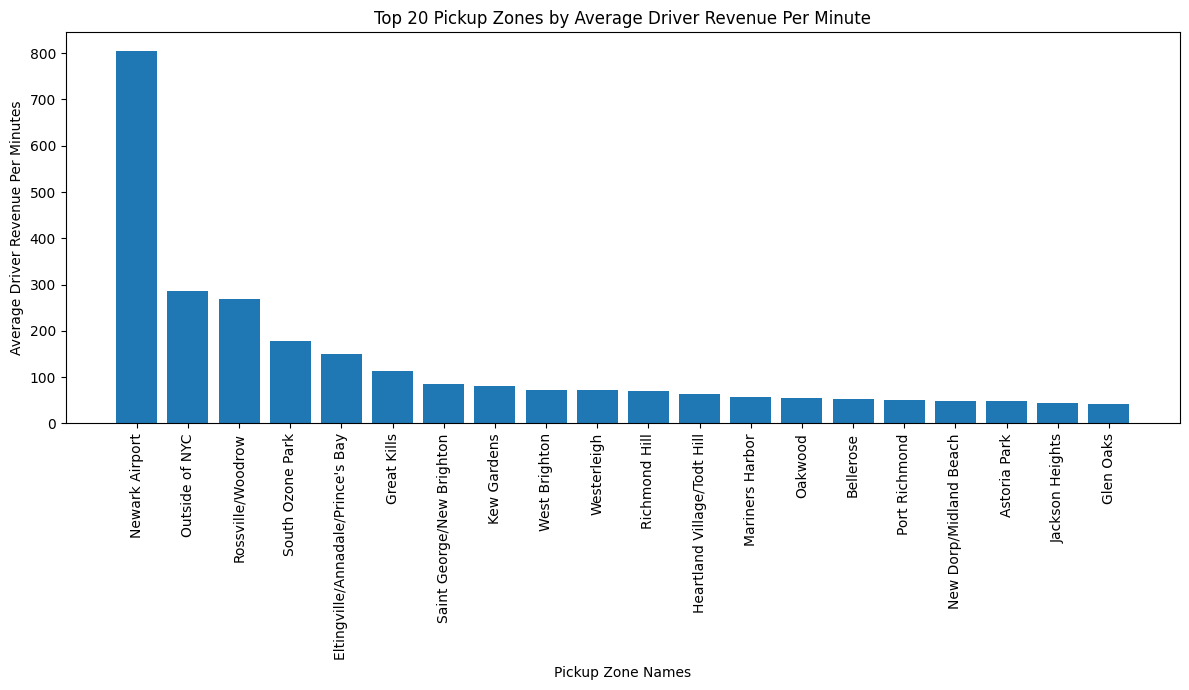

In [ ]:
import matplotlib.pyplot as plt

# Convert only the top 50 pickup zones to Pandas
pickup_plot = (
    pickup_zone_analysis
    .orderBy("avg_driver_revenue_per_minute", ascending=False)
    .limit(20)
    .toPandas()
)

# Plot
plt.figure(figsize=(12, 7))

plt.bar(
    pickup_plot["zone_name"].astype(str),
    pickup_plot["avg_driver_revenue_per_minute"]
)

plt.xlabel("Pickup Zone Names")
plt.ylabel("Average Driver Revenue Per Minutes")
plt.title("Top 20 Pickup Zones by Average Driver Revenue Per Minute")

plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(
    os.path.join(FIGURE_DIR, "Top_20_Pickup_Zones_by_Average_Driver_Revenue_Per_Minute.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [ ]:
from pyspark.sql import functions as F

dropoff_zone_analysis = (

    df_filtered

    .groupBy("DOLocationID")

    .agg(
        F.count("*").alias("dropoff_trip_count"),

        F.sum("driver_revenue").alias("total_destination_revenue"),

        F.avg("driver_revenue").alias("avg_destination_revenue"),

        F.avg("driver_revenue_per_minute").alias(
            "avg_driver_revenue_per_minute"
        )
    )

    # Add drop-off zone name
    .join(
        tax_zone_lookup_spark.select(
            F.col("LocationID").alias("DOLocationID"),
            F.col("Zone").alias("zone_name")
        ),
        on="DOLocationID",
        how="left"
    )

    .select(
        "DOLocationID",
        "zone_name",
        "dropoff_trip_count",
        "total_destination_revenue",
        "avg_destination_revenue",
        "avg_driver_revenue_per_minute"
    )

    .orderBy(F.desc("dropoff_trip_count"))
)

dropoff_zone_analysis = dropoff_zone_analysis.filter(
    F.col("DOLocationID") != 264
)

dropoff_zone_analysis.show(20, truncate=False)

+------------+-----------------------------+------------------+-------------------------+-----------------------+-----------------------------+
|DOLocationID|zone_name                    |dropoff_trip_count|total_destination_revenue|avg_destination_revenue|avg_driver_revenue_per_minute|
+------------+-----------------------------+------------------+-------------------------+-----------------------+-----------------------------+
|236         |Upper East Side North        |18685156          |3.045496140799873E8      |16.299013724048507     |2.1490068653705916           |
|237         |Upper East Side South        |18000800          |2.7870184557999355E8     |15.482747743433267     |2.155350832627636            |
|161         |Midtown Center               |15653614          |2.897353643200041E8      |18.509167551978994     |2.69867861787446             |
|170         |Murray Hill                  |12575028          |2.2538338284000316E8     |17.923091927906892     |2.797850931608985      

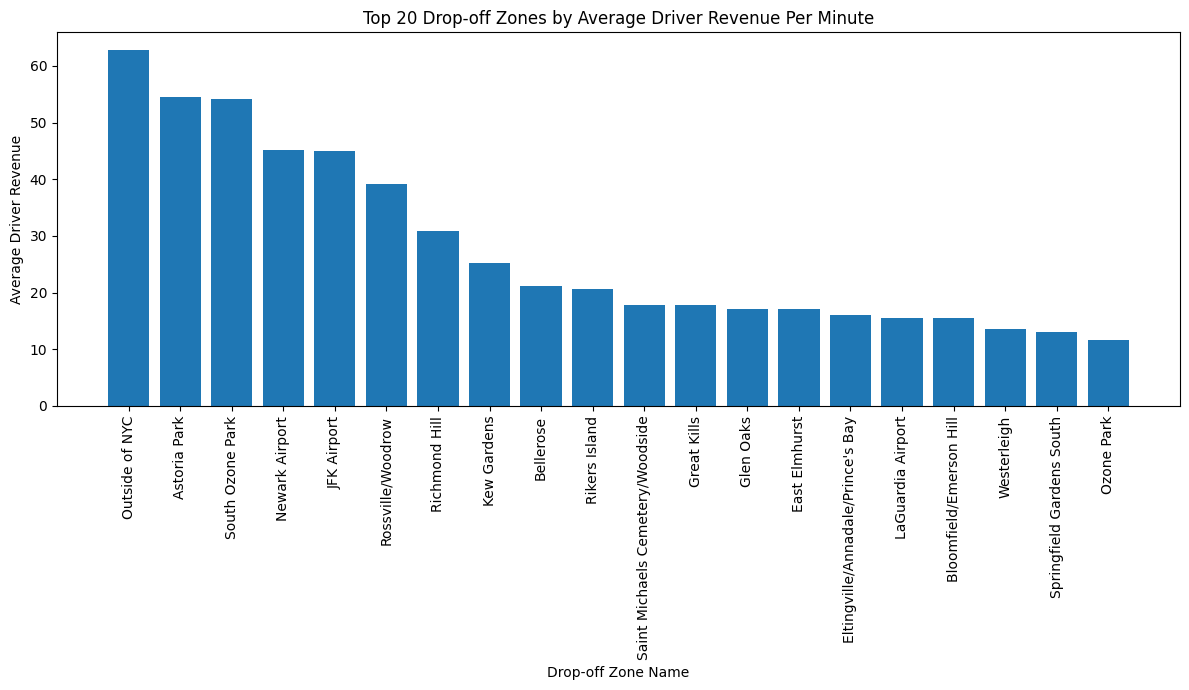

In [ ]:
import matplotlib.pyplot as plt

# Convert only the top 50 drop-off zones to Pandas
dropoff_plot = (
    dropoff_zone_analysis
    .orderBy("avg_driver_revenue_per_minute", ascending=False)
    .limit(20)
    .toPandas()
)

# Plot
plt.figure(figsize=(12, 7))

plt.bar(
    dropoff_plot["zone_name"].astype(str),
    dropoff_plot["avg_driver_revenue_per_minute"]
)

plt.xlabel("Drop-off Zone Name")
plt.ylabel("Average Driver Revenue")
plt.title("Top 20 Drop-off Zones by Average Driver Revenue Per Minute")

plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(
    os.path.join(FIGURE_DIR, "Top_20_dropoff_Zones_by_Average_Driver_Revenue_Per_Minute.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [11]:
route_analysis = (
    df_filtered
    .filter(
        (F.col("PULocationID") != 264) &
        (F.col("DOLocationID") != 264)
    )
    .groupBy("PULocationID", "DOLocationID")
    .agg(
        F.count("*").alias("trip_count"),
        F.sum("driver_revenue").alias("total_driver_revenue"),
        F.avg("driver_revenue").alias("avg_driver_revenue"),
        F.avg("driver_revenue_per_minute").alias(
            "avg_driver_revenue_per_minute"
        )
    )
)

# Add pickup zone name
route_analysis = (
    route_analysis
    .join(
        tax_zone_lookup_spark.select(
            F.col("LocationID").alias("PULocationID"),
            F.col("Zone").alias("pickup_zone")
        ),
        on="PULocationID",
        how="left"
    )
)

# Add dropoff zone name
route_analysis = (
    route_analysis
    .join(
        tax_zone_lookup_spark.select(
            F.col("LocationID").alias("DOLocationID"),
            F.col("Zone").alias("dropoff_zone")
        ),
        on="DOLocationID",
        how="left"
    )
)

route_analysis = (
    route_analysis
    .select(
        "PULocationID",
        "pickup_zone",
        "DOLocationID",
        "dropoff_zone",
        "trip_count",
        "total_driver_revenue",
        "avg_driver_revenue",
        "avg_driver_revenue_per_minute"
    )
    .orderBy(F.desc("trip_count"))
)

route_analysis.show(20, truncate=False)

+------------+----------------------------+------------+-------------------------+----------+--------------------+------------------+-----------------------------+
|PULocationID|pickup_zone                 |DOLocationID|dropoff_zone             |trip_count|total_driver_revenue|avg_driver_revenue|avg_driver_revenue_per_minute|
+------------+----------------------------+------------+-------------------------+----------+--------------------+------------------+-----------------------------+
|237         |Upper East Side South       |236         |Upper East Side North    |2905660   |3.2558593940000482E7|11.205231837173132|1.8104230921377686           |
|236         |Upper East Side North       |237         |Upper East Side South    |2491906   |2.9255325200000312E7|11.740139957125313|1.6614713162497174           |
|237         |Upper East Side South       |237         |Upper East Side South    |2011532   |1.958063046000027E7 |9.734187902554009 |7.166914768725996            |
|236         |Up

In [ ]:
from graphframes import GraphFrame
from pyspark.sql import functions as F

# ============================================================
# Vertices = taxi zones
# ============================================================

vertices = (
    df
    .select(F.col("PULocationID").alias("id"))
    .union(
        df.select(F.col("DOLocationID").alias("id"))
    )
    .filter(F.col("id").isNotNull())
    .distinct()
)

# ============================================================
# Edges = aggregated routes
# ============================================================

edges = (
    route_analysis
    .select(
        F.col("PULocationID").alias("src"),
        F.col("DOLocationID").alias("dst"),
        "trip_count",
        "total_driver_revenue",
        "avg_driver_revenue",
        "avg_driver_revenue_per_minute"
    )
)

# ============================================================
# Create GraphFrame
# ============================================================

g = GraphFrame(vertices, edges)

print("Number of zones:", g.vertices.count())
print("Number of routes:", g.edges.count())

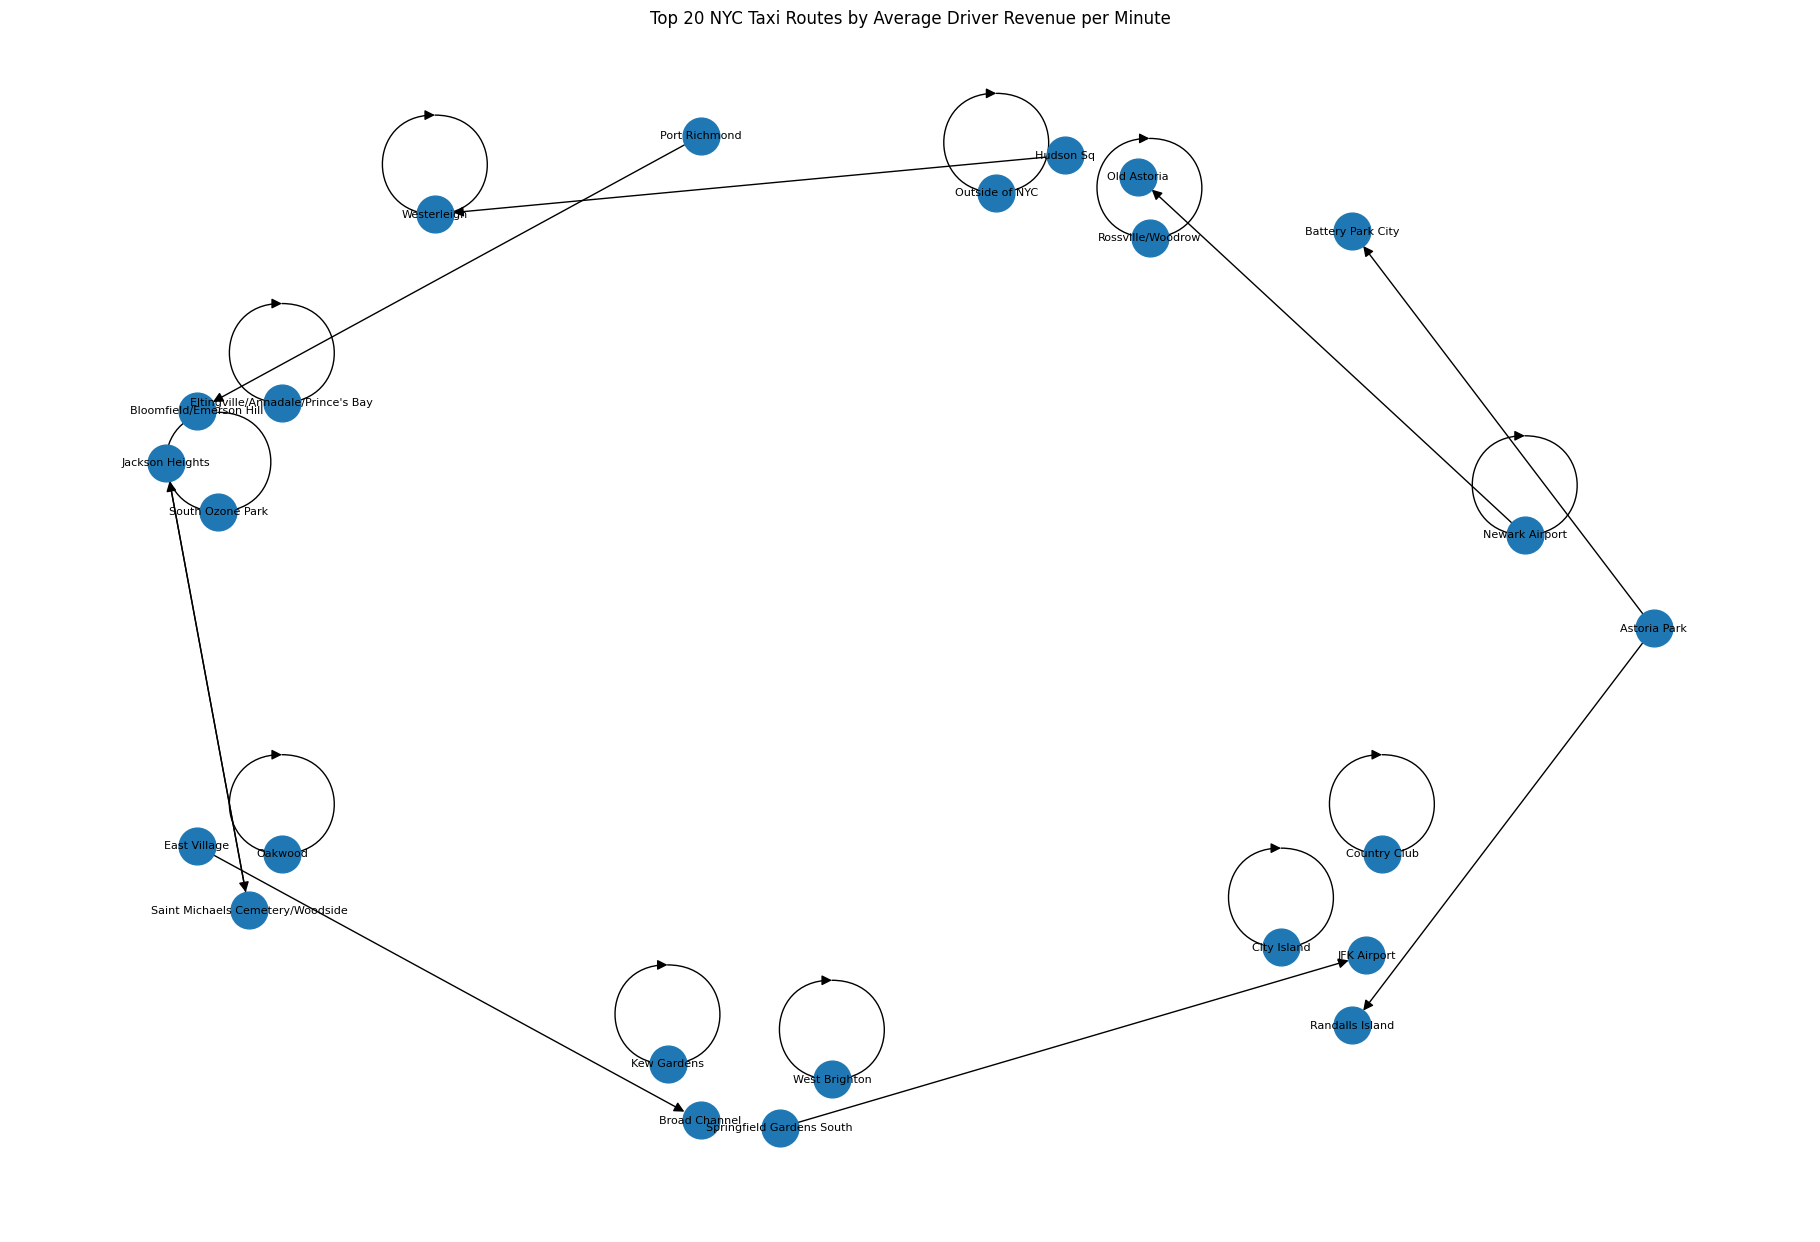

In [16]:
import networkx as nx
import matplotlib.pyplot as plt

# Take only the top 20 routes by average driver revenue per minute
top_routes = (
    route_analysis
    .orderBy(F.desc("avg_driver_revenue_per_minute"))
    .limit(20)
)

# Bring only these 20 routes to Pandas
top_routes_pd = top_routes.toPandas()

# Create NetworkX graph
G = nx.DiGraph()

# Add edges
for _, row in top_routes_pd.iterrows():
    G.add_edge(
        row["pickup_zone"],
        row["dropoff_zone"],
        revenue=row["avg_driver_revenue_per_minute"]
    )

# Draw graph
plt.figure(figsize=(18, 12))

# Better layout for long zone names
pos = nx.kamada_kawai_layout(G)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=700,
    arrows=True,
    font_size=8,
    arrowsize=15,
    node_shape="o"
)

plt.title(
    "Top 20 NYC Taxi Routes by Average Driver Revenue per Minute"
)

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Top_20_NYC_Taxi_Routes_by_Average_Driver_Revenue_Per_Minute.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
df_264 = (
    df
    .filter(F.col("DOLocationID") == 264)
    .orderBy(F.desc("driver_revenue_per_minute"))
)

df_264.show(10, truncate=False)

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+--------------------+--------------+-------------------------+
|vendorid|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|ratecodeid|store_and_fwd_flag|pulocationid|dolocationid|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|airport_fee|cbd_congestion_fee|duration_minutes    |driver_revenue|driver_revenue_per_minute|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+-------